# 05 · Figures and tables for the paper

**What this step does.** Reads every result CSV and writes the paper's exhibits to `figures/` (PDF + PNG) and LaTeX tables to `figures/tables/`. Nothing here recomputes results, so figures always match the CSVs.

| Exhibit | Answers | File |
|---|---|---|
| Fig. 1 | H1 dose recovery | `fig1_dose_recovery.pdf` |
| Fig. 2 | H2 targeted harm vs. overall AUC | `fig2_targeted_harm.pdf` |
| Table 1 | H3 global vs. stratum audit | `tables/tab_h3_audit.tex` |
| Fig. 3 | H3b group-level rate check: stratum vs. global | `fig3_rate_check.pdf` |
| Fig. 4 | H4 recovery by repair (incl. expert review) | `fig4_recovery.pdf` |
| Fig. 5 | Localization (edges into label) | `fig5_localize.pdf` |

In [5]:
# --- setup: run this cell first -------------------------------------------
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, str(Path.cwd()))          # li_lib.py sits next to the notebooks
import li_lib as li
pd.set_option("display.width", 160, "display.max_columns", 30)
print("li_lib", li.VERSION, "| project folder:", li.ROOT)
li.versions()
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.bbox": "tight", "savefig.dpi": 300})
(li.FIGURES / "tables").mkdir(exist_ok=True)
det = pd.read_csv(li.RESULTS / "03_detect_summary.csv")
ver = pd.read_csv(li.RESULTS / "04_verify.csv")
#column names from file, do not change
COL = {"uniform": "#4C72B0", "class_conditional": "#DD8452", "targeted": "#C44E52"}
#NAMES = {"diabetes130": "Diabetes 130", "cdcdiabetes": "CDC Diabetes", "southgerman": "South German Credit"}
NAMES = {"diabetes130": "Diabetes 130", "cdcdiabetes": "CDC Diabetes", "southgerman": "South German Credit", "taiwancredit": "Taiwan Credit"}
DS = [d for d in li.CONFIGS if d in det.dataset.unique()]
def panels(n=len(DS), h=2.6, **kw):
    fig, axes = plt.subplots(1, n, figsize=(2.5 * n + 0.5, h), squeeze=False, **kw)
    return fig, axes[0]
def savefig(fig, stem):
    for ext in ("pdf", "png"):
        fig.savefig(li.FIGURES / f"{stem}.{ext}")
    print("saved", stem)

li_lib 1.1.0 | project folder: D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity


## Fig. 1 · H1 dose recovery (estimate above clean floor vs. injected global share; mean ± 95% CI over seeds)

saved fig1_dose_recovery


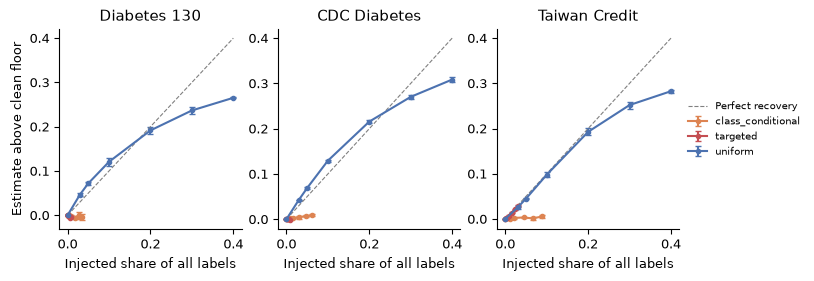

In [6]:
base = det[det.dose == 0][["dataset", "mechanism", "seed", "est_noise"]]
h1 = det.merge(base, on=["dataset", "mechanism", "seed"], suffixes=("", "_0"))
h1["above"] = h1.est_noise - h1.est_noise_0
fig, axes = panels()
for ax, d in zip(axes, DS):
    g = h1[h1.dataset == d]
    for m, gm in g.groupby("mechanism"):
        a = gm.groupby("dose").agg(x=("realized_global_fraction", "mean"), y=("above", "mean"),
                                   se=("above", "sem")).reset_index()
        ax.errorbar(a.x, a.y, yerr=1.96 * a.se.fillna(0), marker="o", ms=3, capsize=2, color=COL[m], label=m)
    lim = max(g.realized_global_fraction.max(), 0.01)
    ax.plot([0, lim], [0, lim], ls="--", lw=0.8, color="grey", label="Perfect recovery")
    ax.set(title=NAMES[d], xlabel="Injected share of all labels")
axes[0].set_ylabel("Estimate above clean floor")
axes[-1].legend(frameon=False, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
savefig(fig, "fig1_dose_recovery")

## Fig. 2 · H2 targeted noise: stratum recall falls while overall AUC holds (model B, no repair)

saved fig2_targeted_harm


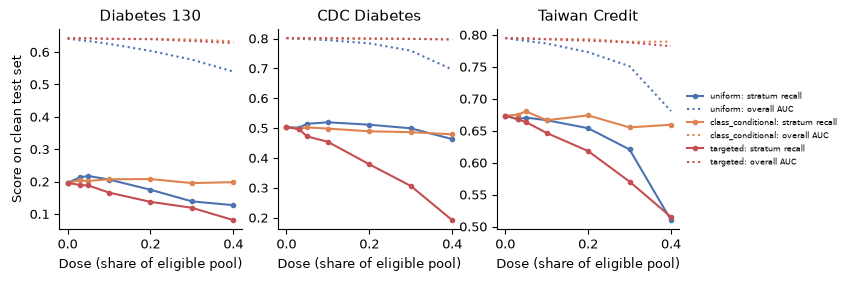

In [7]:
nr = ver[ver.repair == "none"]
fig, axes = panels()
for ax, d in zip(axes, DS):
    g = nr[nr.dataset == d]
    for m in li.MECHANISMS:
        a = g[g.mechanism == m].groupby("dose")[["auc", "recall_stratum"]].mean()
        ax.plot(a.index, a.recall_stratum, marker="o", ms=3, color=COL[m], label=f"{m}: stratum recall")
        ax.plot(a.index, a.auc, ls=":", color=COL[m], label=f"{m}: overall AUC")
    ax.set(title=NAMES[d], xlabel="Dose (share of eligible pool)")
axes[0].set_ylabel("Score on clean test set")
axes[-1].legend(frameon=False, fontsize=6, loc="center left", bbox_to_anchor=(1, 0.5))
savefig(fig, "fig2_targeted_harm")

## Table 1 · H3 audits under targeted noise (precision / recall inside the stratum, mean over seeds)

In [8]:
cols = {"global_in_stratum": "Global CL", "stratum": "Stratum CL", "budget_ranked": "Review: ranked",
        "budget_random": "Review: random"}
t = det[det.mechanism == "targeted"].groupby(["dataset", "dose"])[
    [f"{k}_{m}" for k in cols for m in ("precision", "recall")]].mean().round(2)
t.columns = pd.MultiIndex.from_tuples([(cols[c.rsplit("_", 1)[0]], c.rsplit("_", 1)[1][:4].title() + ".") for c in t.columns])
(li.FIGURES / "tables" / "tab_h3_audit.tex").write_text(t.to_latex(na_rep="--", float_format="%.2f"))
t

Global CL       Stratum CL       Review: ranked       Review: random      
                      Prec. Reca.      Prec. Reca.          Prec. Reca.          Prec. Reca.
dataset      dose                                                                           
cdcdiabetes  0.00      0.00   NaN       0.00   NaN           0.00   NaN           0.00   NaN
             0.03      0.01  0.17       0.01  0.17           0.02  0.26           0.01  0.08
             0.05      0.02  0.17       0.02  0.17           0.05  0.33           0.01  0.09
             0.10      0.04  0.15       0.04  0.15           0.10  0.31           0.03  0.08
             0.20      0.06  0.11       0.07  0.11           0.17  0.27           0.04  0.07
             0.30      0.07  0.09       0.09  0.09           0.24  0.26           0.07  0.08
             0.40      0.07  0.06       0.10  0.06           0.30  0.24           0.07  0.05
diabetes130  0.00      0.00   NaN       0.00   NaN           0.00   NaN           0.00   NaN
             0.03      0.00  0.00       0.00  0.00           0.01  0.22           0.00  0.04
             0.05      0.00  0.00       0.00  0.00           0.02  0.18           0.01  0.06
             0.10      0.00  0.00       0.00  0.00           0.03  0.14           0.01  0.06
             0.20      0.00  0.00       0.00  0.00           0.07  0.16           0.03  0.06
             0.30      0.00  0.00       0.00  0.00           0.09  0.14           0.04  0.06
             0.40      0.00  0.00       0.00  0.00           0.13  0.16           0.06  0.07
southgerman  0.00      0.00   NaN       0.00   NaN           0.00   NaN           0.00   NaN
             0.03      0.01  0.20       0.01  0.20           0.03  0.20           0.00  0.00
             0.05      0.02  0.30       0.02  0.30           0.10  0.30           0.03  0.10
             0.10      0.08  0.52       0.07  0.52           0.27  0.32           0.13  0.16
             0.20      0.12  0.34       0.10  0.34           0.33  0.20           0.13  0.08
             0.30      0.16  0.37       0.15  0.37           0.47  0.20           0.20  0.09
             0.40      0.21  0.33       0.20  0.33           0.50  0.16           0.17  0.05
taiwancredit 0.00      0.00   NaN       0.00   NaN           0.00   NaN           0.00   NaN
             0.03      0.03  0.31       0.02  0.31           0.07  0.36           0.03  0.14
             0.05      0.04  0.30       0.03  0.30           0.10  0.34           0.02  0.08
             0.10      0.07  0.26       0.05  0.26           0.19  0.31           0.04  0.07
             0.20      0.11  0.18       0.08  0.18           0.30  0.24           0.09  0.07
             0.30      0.14  0.14       0.10  0.14           0.42  0.22           0.12  0.07
             0.40      0.13  0.09       0.10  0.09           0.51  0.21           0.17  0.07

## Fig. 3 · H3b group-level rate check: share of seeds flagged 'rate too low' (p < 0.05), targeted noise

saved fig3_rate_check


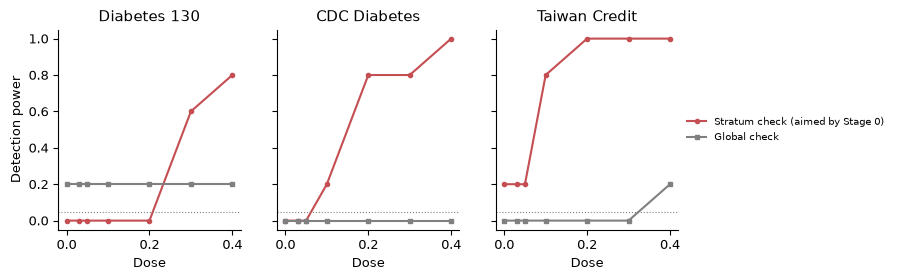

In [10]:
a = li.RATE_CHECK_ALPHA
tg = det[det.mechanism == "targeted"].assign(g=lambda x: x.rate_global_p < a, s=lambda x: x.rate_stratum_p < a)
fig, axes = panels(sharey=True)
for ax, d in zip(axes, DS):
    p = tg[tg.dataset == d].groupby("dose")[["g", "s"]].mean()
    ax.plot(p.index, p.s, marker="o", ms=3, color="#C44E52", label="Stratum check (aimed by Step 0)")
    ax.plot(p.index, p.g, marker="s", ms=3, color="gray", label="Global check")
    ax.axhline(a, ls=":", lw=0.8, color="gray")
    ax.set(title=NAMES[d], xlabel="Dose", ylim=(-0.05, 1.05))
axes[0].set_ylabel("Detection power")
axes[-1].legend(frameon=False, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
savefig(fig, "fig3_rate_check")

## Fig. 4 · H4 recovery ratio of stratum recall by audit and repair (targeted noise, damage ≥ 0.05)

saved fig4_recovery


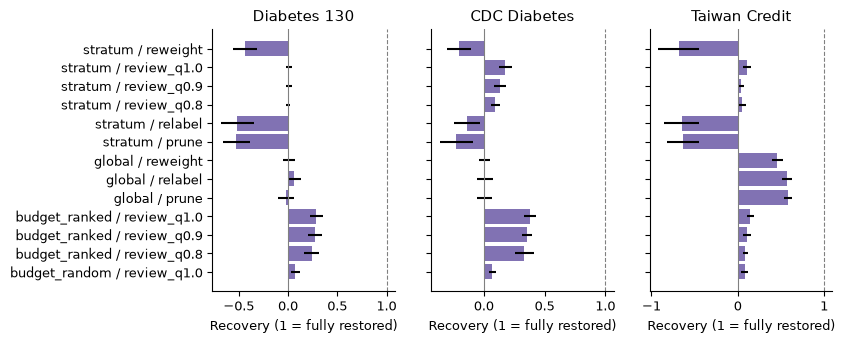

In [11]:
rec = pd.read_csv(li.RESULTS / "04_recovery_recall_stratum.csv")
r = rec[(rec.mechanism == "targeted")].dropna(subset=["recovery_recall_stratum"])
fig, axes = panels(h=3.4, sharey=True)
for ax, d in zip(axes, DS):
    g = r[r.dataset == d]
    if g.empty:
        ax.set_title(NAMES[d] + " (damage too small)"); continue
    a = g.groupby(["audit", "repair"])["recovery_recall_stratum"].agg(["mean", "sem"]).reset_index()
    a["lab"] = a.audit + " / " + a.repair
    ax.barh(a.lab, a["mean"], xerr=1.96 * a["sem"].fillna(0), color="#8172B3")
    ax.axvline(0, color="grey", lw=0.8); ax.axvline(1, color="grey", lw=0.8, ls="--")
    ax.set(title=NAMES[d], xlabel="Recovery (1 = fully restored)")
savefig(fig, "fig4_recovery")

## Fig. 5 · Localization: edges into the label vs. dose (seed 0)

saved fig5_localize


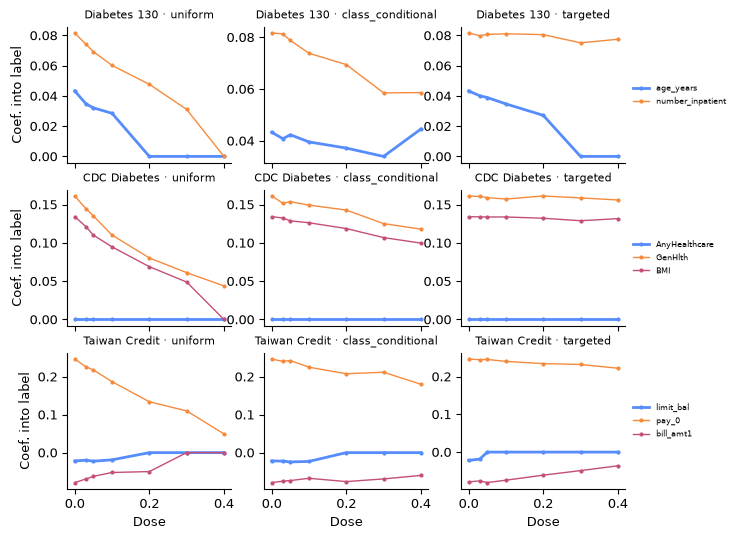

In [12]:
loc = pd.read_csv(li.RESULTS / "03b_localize.csv")
#focus = {"diabetes130": "age_years", "cdcdiabetes": "AnyHealthcare", "southgerman": "age_years"}
focus = {"diabetes130": "age_years", "cdcdiabetes": "AnyHealthcare", "southgerman": "age_years", "taiwancredit": "limit_bal"}
fig, axes = plt.subplots(len(DS), 3, figsize=(7.2, 2.0 * len(DS)), sharex=True, squeeze=False)
for i, d in enumerate(DS):
    gd = loc[loc.dataset == d]
    top = gd[gd.dose == 0].assign(a=lambda x: x.coef_into_label.abs()).nlargest(5, "a").variable.tolist()
    top = list(dict.fromkeys([focus[d]] + top))[:5]
    for j, m in enumerate(li.MECHANISMS):
        ax = axes[i, j]
        for v in top:
            gv = gd[(gd.mechanism == m) & (gd.variable == v)]
            ax.plot(gv.dose, gv.coef_into_label, marker="o", ms=2, lw=2 if v == focus[d] else 1, label=v)
        ax.set_title(f"{NAMES[d]} · {m}", fontsize=8)
        if j == 0: ax.set_ylabel("Coef. into label")
        if i == len(DS) - 1: ax.set_xlabel("Dose")
    axes[i, 2].legend(frameon=False, fontsize=6, loc="center left", bbox_to_anchor=(1, 0.5))
savefig(fig, "fig5_localize")